# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. **Select a GPU runtime before running this notebook.** 

Original fastbook exercise notebook linked by Part 1. Public MovieLens/MNIST data download automatically. QUICK_RUN uses a subset of the real data and one training epoch per model. Book text and code retain their upstream licenses; see LICENSE_FASTBOOK.

Source: https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/clean/13_convolutions.ipynb

In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '03_fastai', 'book', '16_convolutions.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: /content/HaiLong_Colab_Exercises/03_fastai
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/03_fastai/results


## Full exercise evidence

- Run all exercise cells top to bottom in hosted Colab and preserve their outputs, errors and execution counts.
- Keep QUICK_RUN=False; shortened checks or synthetic replacements for real datasets do not count as full original exercises.
- Preserve plots, models, metrics and run configurations in Drive; a final-cell marker alone is insufficient.

- Run six normalization/order configurations on all 60,000 training and 10,000 validation MNIST images for five epochs across three seeds; retain metrics, paired order differences, seed variability, histories, models, activation plots and interpretation references.

- Worked objective answers are present as labeled learning notes; review them alongside saved coding outputs. Retain empty learner-only observations/personal reflection until supplied by the learner. Prepared prose is not hosted execution or independent recall evidence.

This cell describes evidence to collect; it does not certify completion. GPU batch caps preserve dataset coverage and epoch counts, but are documented configuration changes.

- Run the pinned original deterministic convolution workbook's Colab formula dependency exercise, verify all cached/formula values, trace real cell precedents, perturb one original input pixel in memory and save numerical/graph evidence. Label Excel UI Trace Precedents unperformed.


In [2]:
import fastbook  # Installed by the Colab setup cell.

In [3]:
#hide
from fastai.vision.all import *
from fastbook import *

matplotlib.rc('image', cmap='Greys')

def course_image_files(folder):
    images = get_image_files(folder)
    if not QUICK_RUN: return images
    # Keep every digit and both splits, using real MNIST images for the quick check.
    counts, selected = {}, []
    for image in sorted(images):
        group = (image.parent.parent.name, image.parent.name)
        if counts.get(group, 0) < 128:
            selected.append(image)
            counts[group] = counts.get(group, 0) + 1
    return L(selected)

# Convolutional Neural Networks

## The Magic of Convolutions

In [4]:
top_edge = tensor([[-1,-1,-1],
                   [ 0, 0, 0],
                   [ 1, 1, 1]]).float()

In [5]:
path = untar_data(URLs.MNIST_SAMPLE)

<div><progress max="3214948" value="3219456"></progress> 100.14% [3219456/3214948 00:00&lt;00:00]</div>

In [6]:
#hide
Path.BASE_PATH = path

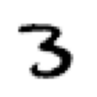

In [7]:
im3 = Image.open(path/'train'/'3'/'12.png')
show_image(im3);

In [8]:
im3_t = tensor(im3)
im3_t[0:3,0:3] * top_edge

tensor([[-0., -0., -0.],
        [0., 0., 0.],
        [0., 0., 0.]])

In [9]:
(im3_t[0:3,0:3] * top_edge).sum()

tensor(0.)

In [10]:
df = pd.DataFrame(im3_t[:10,:20])
df.style.set_properties(**{'font-size':'6pt'}).background_gradient('Greys')

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,12,99,91,142,155,246,182,155,155,155,155,131,52,0,0,0,0
6,0,0,0,138,254,254,254,254,254,254,254,254,254,254,254,252,210,122,33,0
7,0,0,0,220,254,254,254,235,189,189,189,189,150,189,205,254,254,254,75,0
8,0,0,0,35,74,35,35,25,0,0,0,0,0,0,13,224,254,254,153,0
9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,90,254,254,247,53,0


In [11]:
(im3_t[4:7,6:9] * top_edge).sum()

tensor(762.)

In [12]:
(im3_t[7:10,17:20] * top_edge).sum()

tensor(-29.)

In [13]:
def apply_kernel(row, col, kernel):
    return (im3_t[row-1:row+2,col-1:col+2] * kernel).sum()

In [14]:
apply_kernel(5,7,top_edge)

tensor(762.)

### Mapping a Convolution Kernel

In [15]:
[[(i,j) for j in range(1,5)] for i in range(1,5)]

[[(1, 1), (1, 2), (1, 3), (1, 4)],
 [(2, 1), (2, 2), (2, 3), (2, 4)],
 [(3, 1), (3, 2), (3, 3), (3, 4)],
 [(4, 1), (4, 2), (4, 3), (4, 4)]]

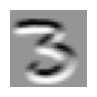

In [16]:
rng = range(1,27)
top_edge3 = tensor([[apply_kernel(i,j,top_edge) for j in rng] for i in rng])

show_image(top_edge3);

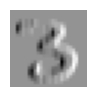

In [17]:
left_edge = tensor([[-1,1,0],
                    [-1,1,0],
                    [-1,1,0]]).float()

left_edge3 = tensor([[apply_kernel(i,j,left_edge) for j in rng] for i in rng])

show_image(left_edge3);

### Convolutions in PyTorch

In [18]:
diag1_edge = tensor([[ 0,-1, 1],
                     [-1, 1, 0],
                     [ 1, 0, 0]]).float()
diag2_edge = tensor([[ 1,-1, 0],
                     [ 0, 1,-1],
                     [ 0, 0, 1]]).float()

edge_kernels = torch.stack([left_edge, top_edge, diag1_edge, diag2_edge])
edge_kernels.shape

torch.Size([4, 3, 3])

In [19]:
mnist = DataBlock((ImageBlock(cls=PILImageBW), CategoryBlock), 
                  get_items=course_image_files, 
                  splitter=GrandparentSplitter(),
                  get_y=parent_label)

dls = mnist.dataloaders(path, num_workers=0)
xb,yb = first(dls.valid)
xb.shape

torch.Size([64, 1, 28, 28])

In [20]:
xb,yb = to_cpu(xb),to_cpu(yb)

In [21]:
edge_kernels.shape,edge_kernels.unsqueeze(1).shape

(torch.Size([4, 3, 3]), torch.Size([4, 1, 3, 3]))

In [22]:
edge_kernels = edge_kernels.unsqueeze(1)

In [23]:
batch_features = F.conv2d(xb, edge_kernels)
batch_features.shape

torch.Size([64, 4, 26, 26])

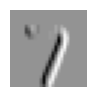

In [24]:
show_image(batch_features[0,0]);

### Strides and Padding

### Understanding the Convolution Equations

## Our First Convolutional Neural Network

### Creating the CNN

In [25]:
simple_net = nn.Sequential(
    nn.Linear(28*28,30),
    nn.ReLU(),
    nn.Linear(30,1)
)

In [26]:
simple_net

Sequential(
  (0): Linear(in_features=784, out_features=30, bias=True)
  (1): ReLU()
  (2): Linear(in_features=30, out_features=1, bias=True)
)

In [27]:
broken_cnn = sequential(
    nn.Conv2d(1,30, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(30,1, kernel_size=3, padding=1)
)

In [28]:
broken_cnn(xb).shape

torch.Size([64, 1, 28, 28])

In [29]:
def conv(ni, nf, ks=3, act=True):
    res = nn.Conv2d(ni, nf, stride=2, kernel_size=ks, padding=ks//2)
    if act: res = nn.Sequential(res, nn.ReLU())
    return res

In [30]:
simple_cnn = sequential(
    conv(1 ,4),            #14x14
    conv(4 ,8),            #7x7
    conv(8 ,16),           #4x4
    conv(16,32),           #2x2
    conv(32,2, act=False), #1x1
    Flatten(),
)

In [31]:
simple_cnn(xb).shape

torch.Size([64, 2])

In [32]:
learn = Learner(dls, simple_cnn, loss_func=F.cross_entropy, metrics=accuracy)

In [33]:
learn.summary()

<div></div>

Sequential (Input shape: 64 x 1 x 28 x 28)
Layer (type)         Output Shape         Param #    Trainable 
                     64 x 4 x 14 x 14    
Conv2d                                    40         True      
ReLU                                                           
____________________________________________________________________________
                     64 x 8 x 7 x 7      
Conv2d                                    296        True      
ReLU                                                           
____________________________________________________________________________
                     64 x 16 x 4 x 4     
Conv2d                                    1168       True      
ReLU                                                           
____________________________________________________________________________
                     64 x 32 x 2 x 2     
Conv2d                                    4640       True      
ReLU                                          

In [34]:
learn.fit_one_cycle(1 if QUICK_RUN else 2, 0.01)

Storage check (before_fit): artifacts 2.548 GB; configured budget 9.000 GB; additional estimate 0.034 GB; runtime free 75.326 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.548 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 75.326 GB. Budget is not Drive quota.


epoch,train_loss,valid_loss,accuracy,time
0,0.064251,0.040596,0.985770,00:08
1,0.022890,0.021390,0.994112,00:07


Storage check (checkpoint_write): artifacts 2.548 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.326 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.548 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.326 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.548 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 75.326 GB. Budget is not Drive quota.


### Understanding Convolution Arithmetic

In [35]:
m = learn.model[0]
m

Sequential(
  (0): Conv2d(1, 4, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (1): ReLU()
)

In [36]:
m[0].weight.shape

torch.Size([4, 1, 3, 3])

In [37]:
m[0].bias.shape

torch.Size([4])

### Receptive Fields

### A Note About Twitter

## Color Images

In [38]:
im = image2tensor(Image.open(image_bear()))
im.shape

torch.Size([3, 1000, 846])

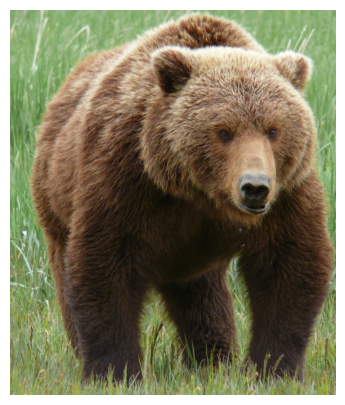

In [39]:
show_image(im);

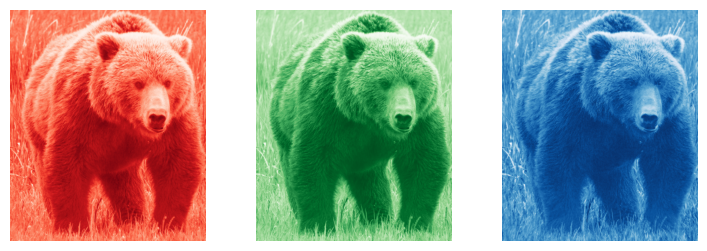

In [40]:
_,axs = subplots(1,3)
for bear,ax,color in zip(im,axs,('Reds','Greens','Blues')):
    show_image(255-bear, ax=ax, cmap=color)

## Improving Training Stability

In [41]:
path = untar_data(URLs.MNIST)

<div><progress max="15683414" value="15687680"></progress> 100.03% [15687680/15683414 00:00&lt;00:00]</div>

In [42]:
#hide
Path.BASE_PATH = path

In [43]:
path.ls()

[Path('testing'), Path('training')]

In [44]:
def get_dls(bs=64):
    return DataBlock(
        blocks=(ImageBlock(cls=PILImageBW), CategoryBlock), 
        get_items=course_image_files, 
        splitter=GrandparentSplitter('training','testing'),
        get_y=parent_label,
        batch_tfms=Normalize()
    ).dataloaders(path, bs=bs, num_workers=0)

dls = get_dls()

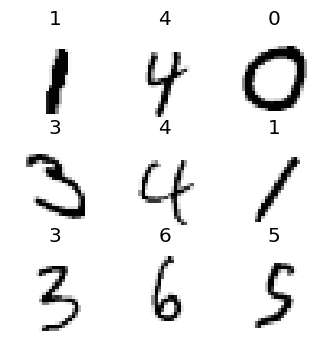

In [45]:
dls.show_batch(max_n=9, figsize=(4,4))

### A Simple Baseline

In [46]:
def conv(ni, nf, ks=3, act=True):
    res = nn.Conv2d(ni, nf, stride=2, kernel_size=ks, padding=ks//2)
    if act: res = nn.Sequential(res, nn.ReLU())
    return res

In [47]:
def simple_cnn():
    return sequential(
        conv(1 ,8, ks=5),        #14x14
        conv(8 ,16),             #7x7
        conv(16,32),             #4x4
        conv(32,64),             #2x2
        conv(64,10, act=False),  #1x1
        Flatten(),
    )

In [48]:
from fastai.callback.hook import *

In [49]:
def fit(epochs=1):
    learn = Learner(dls, simple_cnn(), loss_func=F.cross_entropy,
                    metrics=accuracy, cbs=ActivationStats(with_hist=True))
    learn.fit(epochs, 0.06)
    return learn

In [50]:
learn = fit()

/usr/local/lib/python3.12/dist-packages/fastai/callback/core.py:72: UserWarning: You are shadowing an attribute (modules) that exists in the learner. Use `self.learn.modules` to avoid this
  warn(f"You are shadowing an attribute ({name}) that exists in the learner. Use `self.learn.{name}` to avoid this")


Storage check (before_fit): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.035 GB; runtime free 75.021 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.021 GB. Budget is not Drive quota.


epoch,train_loss,valid_loss,accuracy,time
0,2.303374,2.307618,0.113500,00:43


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.020 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.019 GB. Budget is not Drive quota.


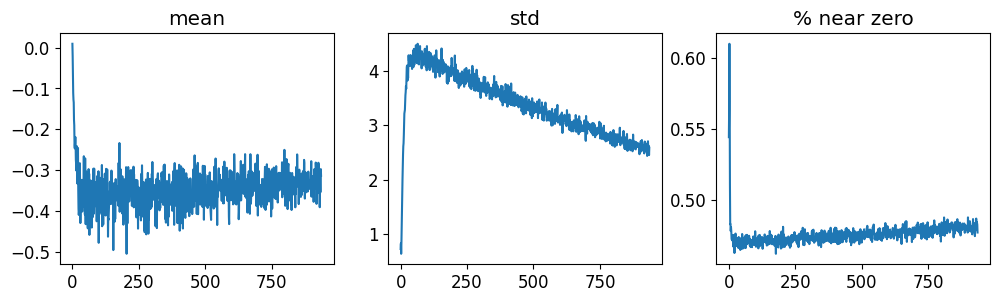

In [51]:
learn.activation_stats.plot_layer_stats(0)

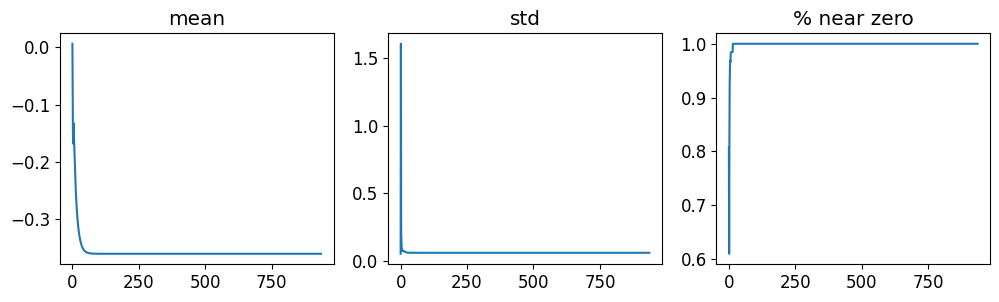

In [52]:
learn.activation_stats.plot_layer_stats(-2)

### Increase Batch Size

In [53]:
dls = get_dls(512)

In [54]:
learn = fit()

Storage check (before_fit): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.035 GB; runtime free 75.020 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.020 GB. Budget is not Drive quota.


epoch,train_loss,valid_loss,accuracy,time
0,0.417492,0.237774,0.927600,00:38


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.019 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.019 GB. Budget is not Drive quota.


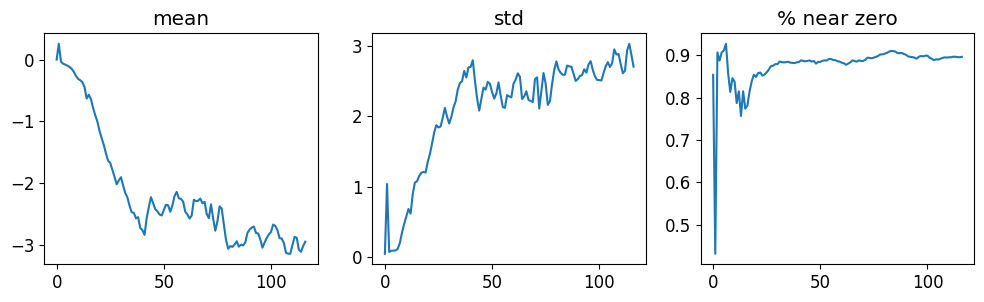

In [55]:
learn.activation_stats.plot_layer_stats(-2)

### 1cycle Training

In [56]:
def fit(epochs=1, lr=0.06):
    learn = Learner(dls, simple_cnn(), loss_func=F.cross_entropy,
                    metrics=accuracy, cbs=ActivationStats(with_hist=True))
    learn.fit_one_cycle(epochs, lr)
    return learn

In [57]:
learn = fit()

Storage check (before_fit): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.035 GB; runtime free 75.019 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.019 GB. Budget is not Drive quota.


epoch,train_loss,valid_loss,accuracy,time
0,0.193121,0.069617,0.979200,00:38


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.019 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.018 GB. Budget is not Drive quota.


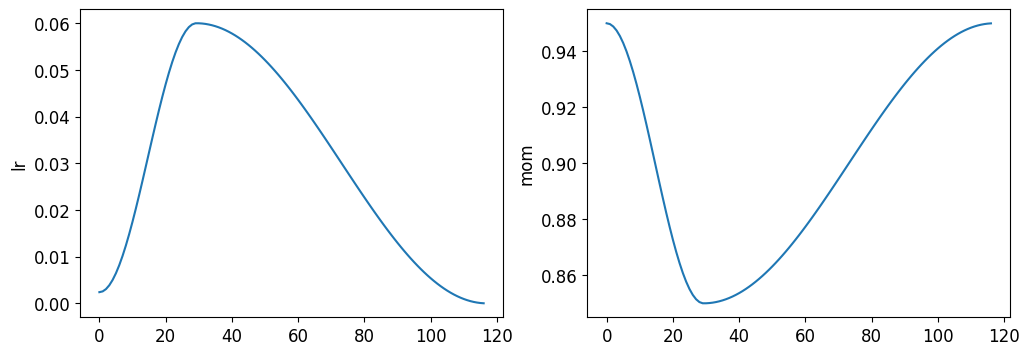

In [58]:
learn.recorder.plot_sched()

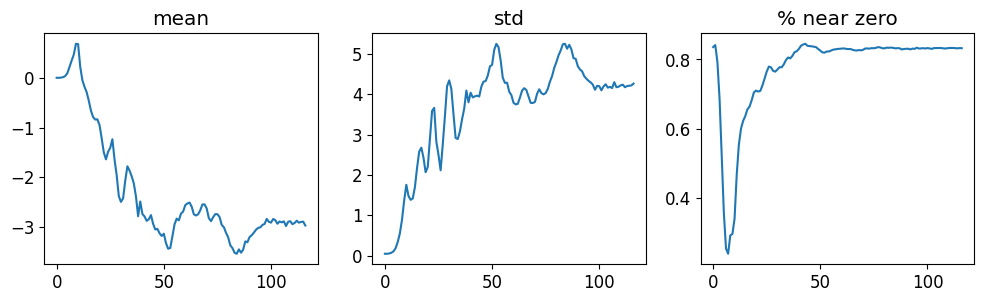

In [59]:
learn.activation_stats.plot_layer_stats(-2)

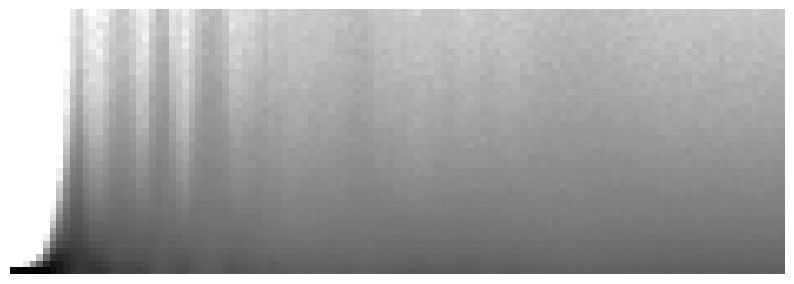

In [60]:
learn.activation_stats.color_dim(-2)

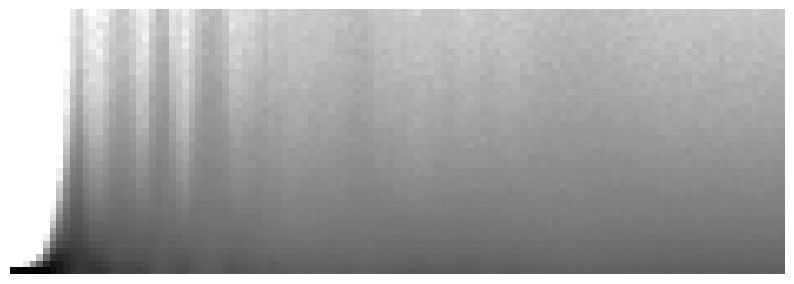

In [61]:
learn.activation_stats.color_dim(-2)

### Batch Normalization

In [62]:
def conv(ni, nf, ks=3, act=True):
    layers = [nn.Conv2d(ni, nf, stride=2, kernel_size=ks, padding=ks//2)]
    if act: layers.append(nn.ReLU())
    layers.append(nn.BatchNorm2d(nf))
    return nn.Sequential(*layers)

In [63]:
learn = fit()

Storage check (before_fit): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.035 GB; runtime free 75.019 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.549 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.019 GB. Budget is not Drive quota.


epoch,train_loss,valid_loss,accuracy,time
0,0.133143,0.056871,0.985200,00:41


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.018 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.018 GB. Budget is not Drive quota.


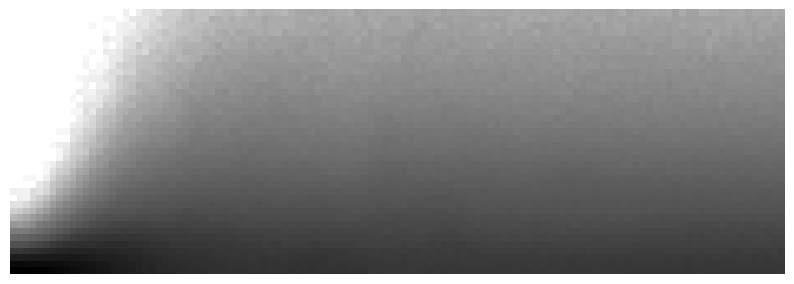

In [64]:
learn.activation_stats.color_dim(-4)

In [65]:
learn = fit(1 if QUICK_RUN else 5, lr=0.1)

Storage check (before_fit): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.035 GB; runtime free 75.018 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.018 GB. Budget is not Drive quota.


epoch,train_loss,valid_loss,accuracy,time
0,0.178599,0.092251,0.970100,00:42
1,0.077702,0.080728,0.974800,00:42
2,0.051449,0.046316,0.985400,00:42
3,0.030818,0.028749,0.991300,00:42
4,0.015537,0.022312,0.992800,00:42


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.018 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.017 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.017 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.017 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.017 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.017 GB. Budget is not Drive quota.


## Conclusions

## Questionnaire

1. What is a "feature"?
1. Write out the convolutional kernel matrix for a top edge detector.
1. Write out the mathematical operation applied by a 3×3 kernel to a single pixel in an image.
1. What is the value of a convolutional kernel apply to a 3×3 matrix of zeros?
1. What is "padding"?
1. What is "stride"?
1. Create a nested list comprehension to complete any task that you choose.
1. What are the shapes of the `input` and `weight` parameters to PyTorch's 2D convolution?
1. What is a "channel"?
1. What is the relationship between a convolution and a matrix multiplication?
1. What is a "convolutional neural network"?
1. What is the benefit of refactoring parts of your neural network definition?
1. What is `Flatten`? Where does it need to be included in the MNIST CNN? Why?
1. What does "NCHW" mean?
1. Why does the third layer of the MNIST CNN have `7*7*(1168-16)` multiplications?
1. What is a "receptive field"?
1. What is the size of the receptive field of an activation after two stride 2 convolutions? Why?
1. Run *conv-example.xlsx* yourself and experiment with *trace precedents*.
1. Have a look at Jeremy or Sylvain's list of recent Twitter "like"s, and see if you find any interesting resources or ideas there.
1. How is a color image represented as a tensor?
1. How does a convolution work with a color input?
1. What method can we use to see that data in `DataLoaders`?
1. Why do we double the number of filters after each stride-2 conv?
1. Why do we use a larger kernel in the first conv with MNIST (with `simple_cnn`)?
1. What information does `ActivationStats` save for each layer?
1. How can we access a learner's callback after training?
1. What are the three statistics plotted by `plot_layer_stats`? What does the x-axis represent?
1. Why are activations near zero problematic?
1. What are the upsides and downsides of training with a larger batch size?
1. Why should we avoid using a high learning rate at the start of training?
1. What is 1cycle training?
1. What are the benefits of training with a high learning rate?
1. Why do we want to use a low learning rate at the end of training?
1. What is "cyclical momentum"?
1. What callback tracks hyperparameter values during training (along with other information)?
1. What does one column of pixels in the `color_dim` plot represent?
1. What does "bad training" look like in `color_dim`? Why?
1. What trainable parameters does a batch normalization layer contain?
1. What statistics are used to normalize in batch normalization during training? How about during validation?
1. Why do models with batch normalization layers generalize better?

### Further Research

### Objective extension: normalization and activation order

The next cell runs controlled comparisons on the full 60,000/10,000 MNIST split: no normalization, BatchNorm, GroupNorm, InstanceNorm and LayerNorm, plus both BatchNorm/activation orders. Each model retains the chapter's five-epoch, learning-rate-0.1 experiment, with three recorded seeds. A common unnormalized output head avoids InstanceNorm's one-pixel-map restriction. Metrics, confusion matrices, activation plots, histories and model states are saved after each run; paired order differences and seed variability are calculated from observed outputs.

[PyTorch's normalization documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.GroupNorm.html), the [BatchNorm paper](https://arxiv.org/abs/1502.03167) and [GroupNorm paper](https://arxiv.org/abs/1803.08494) provide the interpretation references. The original BatchNorm formulation places normalization before nonlinearity; the experiment measures how the two orders behave here without assuming a universal winner. QUICK_RUN is a shortened check, not completion of this extension.


1. What features other than edge detectors have been used in computer vision (especially before deep learning became popular)?
1. There are other normalization layers available in PyTorch. Try them out and see what works best. Learn about why other normalization layers have been developed, and how they differ from batch normalization.
1. Try moving the activation function after the batch normalization layer in `conv`. Does it make a difference? See what you can find out about what order is recommended, and why.

Storage check (before_fit): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.035 GB; runtime free 75.017 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.017 GB. Budget is not Drive quota.


epoch,train_loss,valid_loss,accuracy,time
0,0.416385,0.968219,0.789300,00:37
1,0.635639,0.257219,0.923200,00:37
2,0.258169,0.174950,0.946800,00:37
3,0.143284,0.109270,0.967400,00:37
4,0.094036,0.087850,0.974000,00:38


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.017 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.550 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.016 GB. Budget is not Drive quota.


...

Storage check (checkpoint_write): artifacts 2.557 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.000 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.557 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.000 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.557 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.000 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.557 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.000 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 2.557 GB; configured budget 9.000 GB; additional estimate 0.009 GB; runtime free 75.000 GB. Budget is not Drive quota.


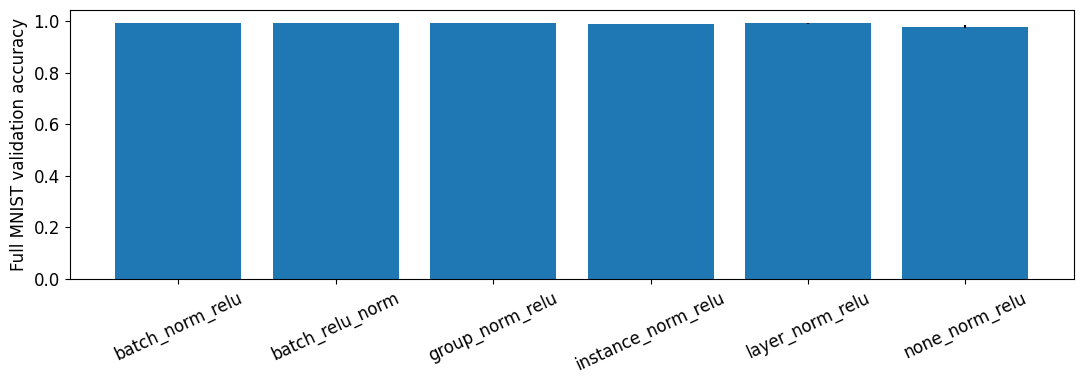

,configuration,mean_accuracy,std_accuracy,mean_cross_entropy,mean_training_seconds
0,batch_norm_relu,0.991667,0.000451,0.025868,239.439369
1,batch_relu_norm,0.992067,0.001155,0.024704,240.609082
2,group_norm_relu,0.990900,0.000265,0.028630,242.119526
3,instance_norm_relu,0.988600,0.001345,0.036616,249.479591
4,layer_norm_relu,0.991067,0.000907,0.029434,244.385442
5,none_norm_relu,0.978833,0.004236,0.071928,217.158351


activation_order,norm_relu,relu_norm,norm_relu_minus_relu_norm
seed,,,
42,0.9912,0.9914,-0.0002
43,0.9921,0.9914,0.0007
44,0.9917,0.9934,-0.0017


{
  "source_rows": {
    "train": 60000,
    "validation": 10000
  },
  "all_digits": 10,
  "epochs_per_model": 5,
  "seeds": [
    42,
    43,
    44
  ],
  "best_observed_configuration": "batch_relu_norm",
  "batchnorm_order_mean_accuracy_difference": -0.0004000067710876465,
  "batchnorm": "Statistics aggregate over the batch and spatial dimensions per channel; evaluation uses running estimates.",
  "groupnorm": "Statistics use channel groups within each sample, so do not depend on other samples in the batch.",
  "instancenorm": "Statistics are computed separately for each sample/channel over spatial dimensions.",
  "layernorm": "This implementation normalizes all channel/spatial features per sample using LayerNorm([C,H,W]).",
  "activation_order": "The original BatchNorm paper applies normalization before nonlinearity; this is a motivated configuration, not a universal empirical winner.",
  "references": [
    "https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html

In [66]:
# Controlled full-MNIST study: normalization type and activation placement.
import json,time,gc
from pathlib import Path
from sklearn.metrics import confusion_matrix
results=Path('results');results.mkdir(exist_ok=True)
def research_cnn(normalization='batch',activation_order='norm_relu'):
    channels=[1,8,16,32,64];blocks=[];height=width=28
    for index,(ni,nf) in enumerate(zip(channels[:-1],channels[1:])):
        ks=5 if index==0 else 3;height=(height+1)//2;width=(width+1)//2
        conv_layer=nn.Conv2d(ni,nf,kernel_size=ks,stride=2,padding=ks//2)
        if normalization=='none':norm=nn.Identity()
        elif normalization=='batch':norm=nn.BatchNorm2d(nf)
        elif normalization=='group':norm=nn.GroupNorm(4,nf)
        elif normalization=='instance':norm=nn.InstanceNorm2d(nf,affine=True,track_running_stats=False)
        elif normalization=='layer':norm=nn.LayerNorm([nf,height,width])
        else:raise ValueError(normalization)
        pair=[norm,nn.ReLU()] if activation_order=='norm_relu' else [nn.ReLU(),norm]
        blocks.append(nn.Sequential(conv_layer,*pair))
    # Same final affine convolution for every option; InstanceNorm is undefined
    # on a one-pixel spatial map, so none of the compared heads is normalized.
    blocks.extend([nn.Conv2d(64,10,kernel_size=3,stride=2,padding=1),Flatten()])
    return nn.Sequential(*blocks)

configurations=[('none','norm_relu'),('batch','relu_norm'),('batch','norm_relu'),
                ('group','norm_relu'),('instance','norm_relu'),('layer','norm_relu')]
research_seeds=[42] if QUICK_RUN else [42,43,44]
research_epochs=1 if QUICK_RUN else 5
research_rows=[]
for seed in research_seeds:
    for normalization,order in configurations:
        set_seed(seed);research_dls=get_dls(512)
        if not QUICK_RUN:
            assert len(research_dls.train.dataset)==60000 and len(research_dls.valid.dataset)==10000
        model=research_cnn(normalization,order)
        stats=ActivationStats(with_hist=True)
        experiment=Learner(research_dls,model,loss_func=F.cross_entropy,metrics=accuracy,cbs=stats)
        started=time.perf_counter();experiment.fit_one_cycle(research_epochs,.1)
        name=f'{normalization}_{order}_seed{seed}'
        # get_preds enters a new fit context and resets Recorder.values.
        # Export the actual training history and activation plot first.
        fit_history=[list(values) for values in experiment.recorder.values]
        assert len(fit_history)==research_epochs and all(len(values)==3 for values in fit_history)
        pd.DataFrame(fit_history,columns=['train_loss','valid_loss','accuracy']).to_csv(results/f'{name}_history.csv',index=False)
        assert len(stats.stats)>0, 'Training activation statistics were not recorded.'
        stats.plot_layer_stats(-2);plt.gcf().savefig(results/f'{name}_activation_stats.png',dpi=120);plt.close()
        # ActivationStats.before_fit also clears its statistics. Exclude only
        # this callback during prediction, then restore it with training stats.
        with experiment.removed_cbs([stats]):
            logits,truth=experiment.get_preds(act=lambda x:x)
        probabilities=logits.softmax(-1);truth=truth.reshape(-1);chosen=logits.argmax(-1)
        assert len(truth)==len(research_dls.valid.dataset)
        measured_accuracy=float((chosen==truth).float().mean())
        measured_loss=float(F.cross_entropy(logits,truth))
        row={'configuration':normalization+'_'+order,'normalization':normalization,'activation_order':order,'seed':seed,
             'epochs':research_epochs,'lr':.1,'batch_size':512,'training_rows':len(research_dls.train.dataset),
             'validation_rows':len(truth),'accuracy':measured_accuracy,'validation_cross_entropy':measured_loss,
             'training_seconds':time.perf_counter()-started,'parameters':sum(p.numel() for p in model.parameters()),
             'normalized_head':False,'quick_run':QUICK_RUN}
        assert np.isfinite(row['validation_cross_entropy'])
        research_rows.append(row)
        pd.DataFrame(confusion_matrix(truth.numpy(),chosen.numpy(),labels=range(10))).to_csv(results/f'{name}_confusion.csv',index=False)
        torch.save({'state_dict':model.state_dict(),'architecture':repr(model),'configuration':row},f'models/{name}.pt')
        pd.DataFrame(research_rows).to_csv(results/'normalization_activation_order_runs.csv',index=False)
        del experiment,model,stats,research_dls;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()

research_frame=pd.DataFrame(research_rows)
summary=research_frame.groupby('configuration').agg(mean_accuracy=('accuracy','mean'),std_accuracy=('accuracy','std'),
 mean_cross_entropy=('validation_cross_entropy','mean'),mean_training_seconds=('training_seconds','mean')).reset_index()
summary['std_accuracy']=summary['std_accuracy'].fillna(0)
summary.to_csv(results/'normalization_activation_order_summary.csv',index=False)
paired=research_frame[research_frame.normalization=='batch'].pivot(index='seed',columns='activation_order',values='accuracy')
paired['norm_relu_minus_relu_norm']=paired['norm_relu']-paired['relu_norm']
paired.to_csv(results/'batchnorm_activation_order_paired_differences.csv')
fig,ax=plt.subplots(figsize=(11,4));ax.bar(summary.configuration,summary.mean_accuracy,yerr=summary.std_accuracy)
ax.tick_params(axis='x',rotation=25);ax.set_ylabel('Full MNIST validation accuracy');fig.tight_layout()
fig.savefig(results/'normalization_activation_order_comparison.png',dpi=150);plt.show()
notes={'source_rows':{'train':60000,'validation':10000},'all_digits':10,'epochs_per_model':research_epochs,
 'seeds':research_seeds,'best_observed_configuration':summary.sort_values('mean_accuracy',ascending=False).iloc[0]['configuration'],
 'batchnorm_order_mean_accuracy_difference':float(paired['norm_relu_minus_relu_norm'].mean()),
 'batchnorm':'Statistics aggregate over the batch and spatial dimensions per channel; evaluation uses running estimates.',
 'groupnorm':'Statistics use channel groups within each sample, so do not depend on other samples in the batch.',
 'instancenorm':'Statistics are computed separately for each sample/channel over spatial dimensions.',
 'layernorm':'This implementation normalizes all channel/spatial features per sample using LayerNorm([C,H,W]).',
 'activation_order':'The original BatchNorm paper applies normalization before nonlinearity; this is a motivated configuration, not a universal empirical winner.',
 'references':['https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html',
 'https://docs.pytorch.org/docs/stable/generated/torch.nn.GroupNorm.html',
 'https://docs.pytorch.org/docs/stable/generated/torch.nn.InstanceNorm2d.html',
 'https://docs.pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html','https://arxiv.org/abs/1502.03167','https://arxiv.org/abs/1803.08494'],
 'limitations':'Three controlled seeds, one MNIST split and architecture; normalization choices can change affine parameter counts. Report measured differences without claiming a universal best order.',
 'questionnaire_Q7_mapping':'Original nested grid/kernel list comprehensions earlier in this notebook',
 'provider_course_completion_claimed':False,'quick_run':QUICK_RUN}
(results/'normalization_activation_order_evidence.json').write_text(json.dumps(notes,indent=2))
display(summary);display(paired);print(json.dumps(notes,indent=2))

Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

## Q18: Colab adaptation of the original workbook's precedent tracing

The original prompt and its Excel wording remain above. The next cell opens an
unchanged, fingerprinted copy of the course's `conv-example.xlsx`, expands its
shared/array cell formulas and evaluates the deterministic `conv-example` sheet
with a restricted parser for its actual `MAX`, `SUM` and `SUMPRODUCT` expressions.
It checks every formula against the saved source values, traces **BM4** through its
actual input pixels/kernel weights and saves the full dependency nodes/edges.

The displayed representative branch explains how first-layer **AH3**, second-layer
**BM4**, pooling **CM4** and output **EN4** relate. A single input pixel **B3** is
changed to 255 in memory; before/after values and the matching Python patch/kernel
calculation are saved. The source workbook is never changed. The random/dropout
sheet is retained in the original file but not recalculated.

This preserves the formula/dependency learning objective in Colab. **Excel's Trace
Precedents interface command and independent learner practice are not claimed.**
[Microsoft's explanation](https://support.microsoft.com/en-us/excel/display-the-relationships-between-formulas-and-cells)
describes the interface relationships; its [precedent API](https://learn.microsoft.com/en-us/office/dev/add-ins/excel/excel-add-ins-ranges-precedents-dependents)
distinguishes direct and recursive links. No official credit/equivalence is asserted.

## Q19: available public resource, with personal interest left open

The original question asks for Jeremy Howard/Sylvain Gugger's Twitter/X likes.
X made likes private in June 2024, as documented in a [primary research study](https://arxiv.org/abs/2601.11140).
The [official announcement](https://x.com/XEng/status/1800634371906380067) was identified,
but direct retrieval during this audit returned 403; no private likes were read.
Use their available public resources as a clearly labeled availability adaptation.
An actual checked official candidate is [fast.ai Lesson 1](https://course.fast.ai/Lessons/lesson1.html),
which links the Jupyter exercises, book and teaching-method discussion. This is an
objective candidate, not a claim either author liked a specific post or that you
personally find it interesting. **Your selected link/reason: __________.**


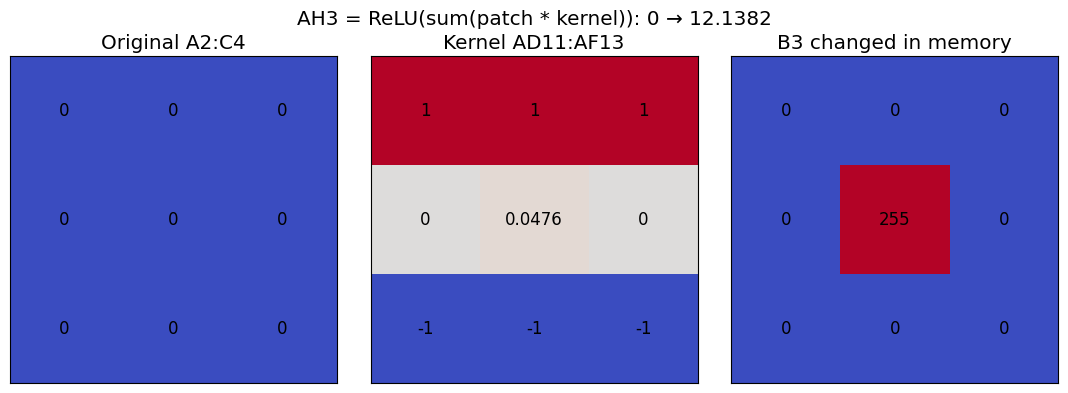

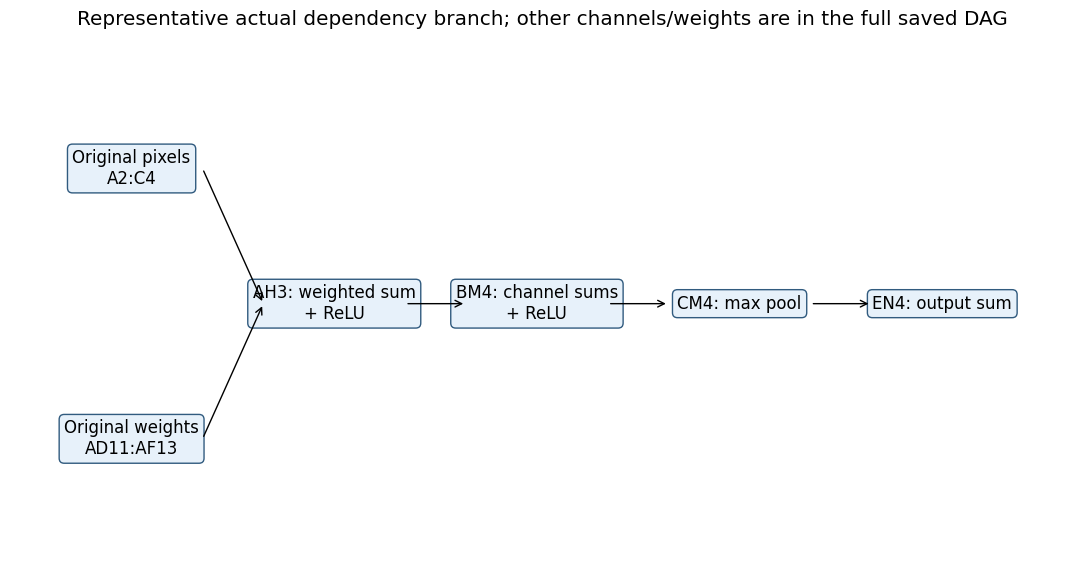

{
  "source_url": "https://github.com/fastai/course22p2/blob/df9323235bc395b5c2f58a3d08b83761947b9b93/xl/conv-example.xlsx",
  "source_sha256": "28d885e8e07e3fb8fbeea49288c17e25edd0f168f0dbdaabd403017e83c15f0b",
  "sheet": "conv-example",
  "formulas_checked": 2865,
  "maximum_absolute_cached_error": 1.7763568394002505e-15,
  "shared_formula_translation_checked": true,
  "array_formula_cells_checked": true,
  "trace_target": "BM4",
  "trace_nodes": 80,
  "trace_edges": 360,
  "direct_precedents": [
    "AH3",
    "AH32",
    "AH33",
    "AH34",
    "AH4",
    "AH5",
    "AI3",
    "AI32",
    "AI33",
    "AI34",
    "AI4",
    "AI5",
    "AJ3",
    "AJ32",
    "AJ33",
    "AJ34",
    "AJ4",
    "AJ5",
    "BI11",
    "BI12",
    "BI13",
    "BI15",
    "BI16",
    "BI17",
    "BJ11",
    "BJ12",
    "BJ13",
    "BJ15",
    "BJ16",
    "BJ17",
    "BK11",
    "BK12",
    "BK13",
    "BK15",
    "BK16",
    "BK17"
  ],
  "python_first_output": 0.0,
  "python_changed_output": 12.138160024

In [67]:
# CPU formula/dependency exercise; original Excel UI action is not performed.
from convolution_workbook_exercise import run_workbook_exercise
convolution_workbook_evidence = run_workbook_exercise(
    COURSE_ROOT / '03_fastai/resources/conv-example.xlsx', Path('results'))


In [68]:
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


## Worked objective answers — preparation notes

These are authored worked answers keyed to the original question numbers above.
They preserve the prompts and teaching code. They do not attest to independent
recall, understanding, personal experience, a hosted run, or course completion.
Code questions point to runnable demonstrations; their execution evidence must
come from saved Colab outputs. Research comparisons remain conditional on those
outputs. No learner reflection or questionnaire form has been filled on your behalf.


### Questionnaire Q1–Q17: convolution geometry

**Q1.** A feature is a measurable pattern useful for prediction. In a CNN, learned
filters turn image patterns into activation maps; later features combine earlier
ones into more complex patterns.

**Q2.** The notebook's top-edge kernel is `[[-1,-1,-1],[0,0,0],[1,1,1]]`.
It subtracts the top-row intensity from the bottom-row intensity. Reversing signs
detects the opposite contrast polarity.

**Q3.** For a patch `X` and kernel `K`, the output is
`sum(X[i,j]*K[i,j] for i in range(3) for j in range(3))`, optionally plus bias.
PyTorch uses this cross-correlation operation without flipping the kernel.

**Q4.** A zero-valued patch gives a zero weighted sum. A layer with a bias returns
that bias, so zero input does not necessarily imply zero layer output.

**Q5.** Padding adds a border to the input before applying a kernel. Zero padding
can control output size and lets boundary pixels participate in more windows.

**Q6.** Stride is the distance the kernel moves between output positions. A larger
stride reduces the spatial output grid.
[PyTorch Conv2d padding and stride](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).

**Q7 — executable demonstration.** The original edge-map cells contain
`[[apply_kernel(i,j,top_edge) for j in rng] for i in rng]`: the inner list makes a
row and the outer list makes the image. This satisfies the nested-comprehension
coding prompt; retain the saved edge-map outputs.

**Q8.** A batched input is `(N,C_in,H,W)`. Weights have shape
`(C_out,C_in/groups,kH,kW)`; for the default `groups=1` every output filter uses
all input channels.
[PyTorch functional convolution](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html).

**Q9.** A channel is one plane of values at each spatial location: one intensity
plane for grayscale, three color planes for RGB, or one learned feature map.

**Q10.** Unfold each local patch into a row and each kernel into a column. Their
matrix product computes the convolution outputs, then these are reshaped into
maps. Convolution imposes local connections and shared kernel weights instead
of a separate weight for every input/output spatial pair.
[PyTorch Unfold](https://docs.pytorch.org/docs/stable/generated/torch.nn.Unfold.html).

**Q11.** A convolutional neural network uses learned convolutions, typically with
nonlinearities and spatial reduction, to learn features and make predictions.

**Q12.** Refactoring a repeated block into a helper such as `conv` makes its
architecture consistent and allows one controlled change to update all intended
blocks. It also makes comparisons easier to inspect.

**Q13.** `Flatten` merges dimensions. Here it retains the batch dimension and
flattens channel/spatial dimensions after the final convolution. A final
`(N,C,1,1)` map becomes `(N,C)` class scores: two in the initial 3-versus-7
classifier and ten in the later all-digit classifier.

**Q14.** NCHW means batch size, channels, height and width, in that order.

**Q15 — correction to the prompt's arithmetic.** In the actual original network,
the third `3x3`, stride-2, padding-1 layer receives `(N,8,7,7)` and outputs
`(N,16,4,4)`. It has `16*8*3*3 + 16 = 1168` parameters. The per-image count of
kernel multiplications is therefore `4*4*(1168-16) = 18,432`, excluding bias
addition. `7*7*(1168-16) = 56,448` would require a 7-by-7 **output** grid; 7-by-7
is this layer's input grid. The original question is preserved, but its count
does not match the supplied stride-2 code. Applying
`floor((7+2*1-(3-1)-1)/2+1)` confirms the output size 4.
[PyTorch output-size formula](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).

**Q16.** A receptive field is the input region that can influence one activation.
Stacking convolutions expands it; strides increase the spacing between centers.

**Q17.** For two `3x3` convolutions, both with stride 2, it is `7x7`: the first
field is 3 with center spacing 2, and the second covers `3+(3-1)*2=7` input
positions. This depends on kernel size; a first `5x5` kernel followed by `3x3`
gives 9, not 7. This is a theoretical field, including any padded positions.

### Questionnaire Q18–Q24: learner activity and image data

**Q18 — learner activity: __________.** Run the spreadsheet and record your own
trace-precedents observation. These notes do not claim to have operated the
spreadsheet or completed your experiment.

**Q19 — learner-selected resource and reason: __________.** This calls for your
choice after browsing the suggested resources. No personal interest, visit or
social-media account interaction is manufactured.

**Q20.** In the notebook's channel-first convention, an RGB image is `(3,H,W)`;
a batch is `(N,3,H,W)`. Channel-last formats also exist and need an explicit
permutation before this model.

**Q21.** A color filter has one spatial kernel for each input channel. Their
weighted patch sums are added, plus bias, to make one output-channel value.
Different filters create different output maps.
[PyTorch functional convolution](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html).

**Q22.** `dls.show_batch()` displays a decoded batch with labels, useful for
checking transforms and target alignment before training.
[fast.ai DataLoaders](https://docs.fast.ai/data.core.html#dataloaders).

**Q23.** A stride-2 layer roughly halves height and width, cutting spatial positions
by four. Doubling channels retains more feature capacity while the next layer's
compute remains manageable. It is a design heuristic, not a shape requirement.

**Q24.** A larger first kernel combines more raw MNIST stroke context before
downsampling. It can help distinguish nearby stroke patterns; whether it improves
accuracy is an empirical architectural choice.

### Questionnaire Q25–Q37: training diagnostics and scheduling

**Q25.** `ActivationStats` collects activation means, standard deviations and a
near-zero fraction from selected layers; `with_hist=True` additionally collects
histograms. The current implementation's threshold is `output <= 0.05`, not
absolute distance from zero, so negative values are counted too.

**Q26.** Access the attached callback through the learner, for example
`learn.activation_stats`, and then call its plotting methods.

**Q27.** `plot_layer_stats` plots mean, standard deviation and near-zero percentage
for one layer. The x-axis follows recorded training batches; it is not a neuron
index.

**Q28.** A persistently inactive ReLU unit has no local gradient through its
negative branch, and pervasive zero activations may block learning. Some sparse
zeros are normal; the diagnostic needs context rather than a zero-free target.

**Q29.** Larger batches can improve hardware throughput and reduce sampling noise,
but need more memory and give fewer optimizer updates for the same number of
examples. They can change normalization statistics and generalization. Retune the
learning rate and compare equivalent data/compute budgets.

**Q30.** Early random features and immature optimizer state can make a large
learning-rate step unstable. Warmup lets useful features and statistics develop
before larger updates. The appropriate starting rate is still data/model dependent.

**Q31.** A 1cycle schedule raises the learning rate to a peak, then lowers it to
a small final value over one training run, often with momentum moving inversely.

**Q32.** A sufficiently large, stable learning rate can speed progress and introduce
an optimization regularization effect. Too large a rate diverges; there is no
universal benefit independent of the model and schedule.

**Q33.** Smaller final updates allow refinement near a solution and reduce
oscillation around it.

**Q34.** Cyclical momentum varies momentum through training. In the usual 1cycle
schedule it decreases as learning rate rises and increases as learning rate falls.
[fast.ai scheduling API](https://docs.fast.ai/callback.schedule.html).

**Q35.** The learner's `Recorder` retains losses, metrics and recorded hyperparameter
history; `ParamScheduler` changes parameters and places its history in
`learn.recorder.hps`. Plot those records to inspect the actual schedule.
[fast.ai Recorder](https://docs.fast.ai/learner.html#recorder).

**Q36.** In `color_dim`, a column is one recorded training-batch activation histogram
for the selected layer. Rows represent histogram bins and color reflects
`log1p(count)`, so it is a distribution trace, not an image example.

**Q37.** Collapse into near-zero bins, abrupt distribution jumps or growing spread
can suggest inactive units or unstable training. A healthy trace should be read
alongside loss and validation metrics; colors alone do not prove success or failure.
[fast.ai activation hooks](https://docs.fast.ai/callback.hook.html#activationstats).

### Questionnaire Q38–Q40: batch normalization

**Q38.** With `affine=True`, batch normalization learns one scale (`gamma`) and
one shift (`beta`) per channel. Running mean/variance are buffers, not trainable
parameters.

**Q39.** During training, BatchNorm2d uses statistics over the batch and spatial
positions separately for each channel. With the default tracked running
statistics, evaluation uses running mean/variance accumulated during training.
If `track_running_stats=False`, evaluation also uses batch statistics.
[PyTorch BatchNorm2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html).

**Q40.** Batch normalization can improve optimization and introduce a stochastic
regularization effect through training-batch statistics. That does not guarantee
better generalization for every architecture, batch size or dataset. The added
controlled study checks this claim instead of assuming a winner.
[original batch-normalization paper](https://arxiv.org/abs/1502.03167).

### Further Research FR1–FR3

**FR1 — other computer-vision features.** Pre-deep-learning pipelines used corners,
keypoints, gradient-orientation descriptors and texture/color summaries. SIFT
describes local neighborhoods around scale-space keypoints, supporting matching
across scale/rotation changes ([Lowe's original paper](https://www.cs.ubc.ca/~lowe/papers/ijcv04.pdf)).
HOG aggregates local gradient orientations over cells/blocks and was developed for
human detection ([Dalal and Triggs](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf)).
These are designed feature transformations; CNNs learn their filters from the
training objective.

**FR2 — normalization alternatives and comparison.** Batch normalization uses
batch/spatial statistics per channel; GroupNorm uses groups of channels within
each example and avoids batch dependence; InstanceNorm uses each example/channel's
spatial statistics; the supplied LayerNorm normalizes that example over its stated
`(C,H,W)` shape. The added study compares these with a no-normalization baseline,
using identical CNN geometry, all 60,000/10,000 MNIST examples, five epochs and
three seeds. Save mean/variability and histories; the best observed configuration
cannot be named before execution.
[GroupNorm paper](https://arxiv.org/abs/1803.08494),
[InstanceNorm API](https://docs.pytorch.org/docs/stable/generated/torch.nn.InstanceNorm2d.html),
[LayerNorm API](https://docs.pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html).

**FR3 — activation order.** The original batch-normalization paper normalizes the
affine transform before the nonlinearity. This normalizes its input distribution;
normalizing after ReLU instead changes a rectified, partly zero distribution.
Both orders can be used in other architectures, so the paper's design is not a
universal proof of superiority. The added paired `batch/relu_norm` and
`batch/norm_relu` experiments keep the remaining architecture/data/schedule fixed
across seeds. Compare their saved paired accuracy/loss differences and activation
plots before drawing a conclusion.
[original batch-normalization paper](https://arxiv.org/abs/1502.03167).

In [69]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null, "base_model_commit": null, "fastai_reuse_evidence": {"contract_version": 1, "notebook": "03_fastai/16_convolutions.ipynb", "source_sha256": "aed6a230824a4bffa759c07af1178e227c6e0c367a4b8791ac897e05b6c4ac58", "helper_sha256": {"03_fastai/convolution_workbook_exercise.py": "ecacb93aef6846c82d6a9eebc4809e1a6766410f04783ac132f247935af3a8fc", "03_fastai/fastai_utils.py": "a03e913e1c07f55aedd56ee6128096f3f952f4f8be22f83c4a22002589c4bd18", "03_fastai/wearable_objective_extension.py": "f9b0a8bf81a5bab8c10aee5e8795e9cef3df58e40925f7705e58301b18b3fbe9", "03_fastai/wearable_utils.py": "6de4ee45118d96e024bd4e0f3fd3552905b38a1ff01c0a5146578bb0d8263db9", "colab_runtime.py": "e11bedb13e1bd71a71c01cc49e558d05c89b057259fe52e64301d0c4d626a140", "course_persistence.py": "f14f7282d4b1e718b01858a61a2dca8b60f5135ba9971fc7923c50bf12cca3d2"}, "persistent_course_root": "/conte